# Model Evaluation — Employee Attrition (Revised)

This notebook compares **seven classification models** for employee attrition prediction. It uses stratified cross-validation on the training set to select the model using **mean F1-score**, then evaluates the selected model and all candidates on one held-out test set.

Models compared:
1. Logistic Regression
2. Random Forest
3. Support Vector Machine (SVM)
4. Gradient Boosting
5. K-Nearest Neighbors (KNN)
6. Decision Tree
7. Extra Trees

**Important:** The test set is used only for final evaluation, not for choosing the model. F1-score is the primary selection metric because the attrition classes are imbalanced; precision, recall, accuracy, ROC-AUC, and PR-AUC are also reported.


In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)


In [2]:
# Locate the prepared dataset from common notebook/project working directories.
data_candidates = [
    Path("../data/employee_attrition_selected.csv"),
    Path("backend/data/employee_attrition_selected.csv"),
    Path("../backend/data/employee_attrition_selected.csv"),
    Path("data/employee_attrition_selected.csv"),
    Path("/mnt/data/employee_attrition_selected.csv"),
]

data_path = next((path for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find employee_attrition_selected.csv. "
        "Update data_candidates to match your project folder."
    )

df = pd.read_csv(data_path)
if "Attrition" not in df.columns:
    raise ValueError("Dataset must contain the target column 'Attrition'.")

df = df.dropna(subset=["Attrition"]).copy()
X = df.drop(columns=["Attrition"])
y_raw = df["Attrition"].astype(str).str.strip()
y = y_raw.map({"Yes": 1, "No": 0})

if y.isna().any():
    raise ValueError("Attrition must contain only 'Yes' and 'No' values.")

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object", "category", "bool"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Imputation and preprocessing are fitted inside each pipeline/fold to prevent leakage.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Dataset shape:", df.shape)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training class counts (0=No, 1=Yes):")
print(y_train.value_counts().sort_index())


Dataset shape: (1470, 33)
Training rows: 1176 | Test rows: 294
Training class counts (0=No, 1=Yes):
Attrition
0    986
1    190
Name: count, dtype: int64


## 1. Define seven models

Class weighting is used where the estimator supports it. Gradient Boosting receives balanced sample weights during fitting to account for the minority attrition class.


In [3]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
        ))
    ]),
    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", GradientBoostingClassifier(random_state=42))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(class_weight="balanced", random_state=42))
    ]),
    "Extra Trees": Pipeline([
        ("preprocessor", preprocessor),
        ("model", ExtraTreesClassifier(
            n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
        ))
    ])
}

print("Models to compare:", len(models))
for model_name in models:
    print("-", model_name)


Models to compare: 7
- Logistic Regression
- Random Forest
- SVM
- Gradient Boosting
- K-Nearest Neighbors
- Decision Tree
- Extra Trees


## 2. Cross-validation on the training set

The mean cross-validation F1-score selects the model. The held-out test set is not used in this step.


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_rows = []
cv_results = {}

# Balanced sample weights for Gradient Boosting, calculated only from training labels.
class_counts = y_train.value_counts()
gb_sample_weights = np.where(
    y_train.to_numpy() == 1,
    len(y_train) / (2 * class_counts[1]),
    len(y_train) / (2 * class_counts[0])
)

for name, model in models.items():
    fit_params = {}
    if name == "Gradient Boosting":
        fit_params["model__sample_weight"] = gb_sample_weights

    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1,
        return_train_score=False, error_score="raise",
        params=fit_params if fit_params else None
    )
    cv_results[name] = {
        "Accuracy": float(np.mean(scores["test_accuracy"])),
        "Precision": float(np.mean(scores["test_precision"])),
        "Recall": float(np.mean(scores["test_recall"])),
        "F1 Score": float(np.mean(scores["test_f1"])),
        "ROC-AUC": float(np.mean(scores["test_roc_auc"])),
        "PR-AUC": float(np.mean(scores["test_average_precision"]))
    }
    cv_rows.append({"Model": name, **cv_results[name]})

cv_evaluation = pd.DataFrame(cv_rows).sort_values(
    by=["F1 Score", "Recall", "ROC-AUC"], ascending=False
).reset_index(drop=True)

display(cv_evaluation.style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}", "Recall": "{:.2%}",
    "F1 Score": "{:.2%}", "ROC-AUC": "{:.2%}", "PR-AUC": "{:.2%}"
}))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,SVM,83.84%,50.56%,60.00%,54.58%,81.16%,59.53%
1,Gradient Boosting,84.52%,52.00%,52.63%,52.15%,79.72%,58.28%
2,Logistic Regression,77.29%,39.34%,71.58%,50.55%,83.20%,64.47%
3,Decision Tree,79.68%,37.34%,37.37%,37.06%,62.60%,24.14%
4,Extra Trees,86.56%,86.63%,21.58%,33.51%,80.68%,55.57%
5,Random Forest,86.73%,92.50%,20.53%,32.57%,82.35%,57.31%
6,K-Nearest Neighbors,85.29%,71.97%,15.79%,25.41%,69.82%,36.19%


## 3. Select the model using cross-validation

The highest **mean CV F1-score** is the primary criterion. Recall and ROC-AUC are tie-breakers. Test-set metrics do not determine this choice.


In [5]:
best_model_name = cv_evaluation.iloc[0]["Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Mean CV F1-score:", f"{cv_results[best_model_name]['F1 Score']:.2%}")


Selected model: SVM
Mean CV F1-score: 54.58%


## 4. Fit candidates and evaluate on the held-out test set

These test metrics estimate how the models perform on unseen data. Use the CV-selected model as the final candidate; do not switch models just because one has a slightly better test score.


In [6]:
predictions = {}
probabilities = {}
test_rows = {}

for name, model in models.items():
    fit_params = {}
    if name == "Gradient Boosting":
        fit_params["model__sample_weight"] = gb_sample_weights

    model.fit(X_train, y_train, **fit_params)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = pred
    probabilities[name] = prob
    test_rows[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob)
    }

test_evaluation = pd.DataFrame([
    {"Model": name, **metrics} for name, metrics in test_rows.items()
]).sort_values(by=["F1 Score", "Recall", "ROC-AUC"], ascending=False).reset_index(drop=True)

display(test_evaluation.style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}", "Recall": "{:.2%}",
    "F1 Score": "{:.2%}", "ROC-AUC": "{:.2%}", "PR-AUC": "{:.2%}"
}))

print("\nCV-selected final model:", best_model_name)
print("Its held-out test metrics:")
display(test_evaluation[test_evaluation["Model"] == best_model_name].style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}", "Recall": "{:.2%}",
    "F1 Score": "{:.2%}", "ROC-AUC": "{:.2%}", "PR-AUC": "{:.2%}"
}))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,SVM,81.97%,45.16%,59.57%,51.38%,81.05%,53.68%
1,Logistic Regression,77.21%,38.64%,72.34%,50.37%,81.88%,55.35%
2,Gradient Boosting,79.59%,38.18%,44.68%,41.18%,77.74%,46.70%
3,Decision Tree,76.19%,24.44%,23.40%,23.91%,54.82%,17.97%
4,Extra Trees,84.69%,58.33%,14.89%,23.73%,82.05%,52.25%
5,Random Forest,84.35%,55.56%,10.64%,17.86%,81.05%,44.42%
6,K-Nearest Neighbors,82.31%,30.77%,8.51%,13.33%,61.42%,24.78%



CV-selected final model: SVM
Its held-out test metrics:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,SVM,81.97%,45.16%,59.57%,51.38%,81.05%,53.68%


## 5. Confusion matrices

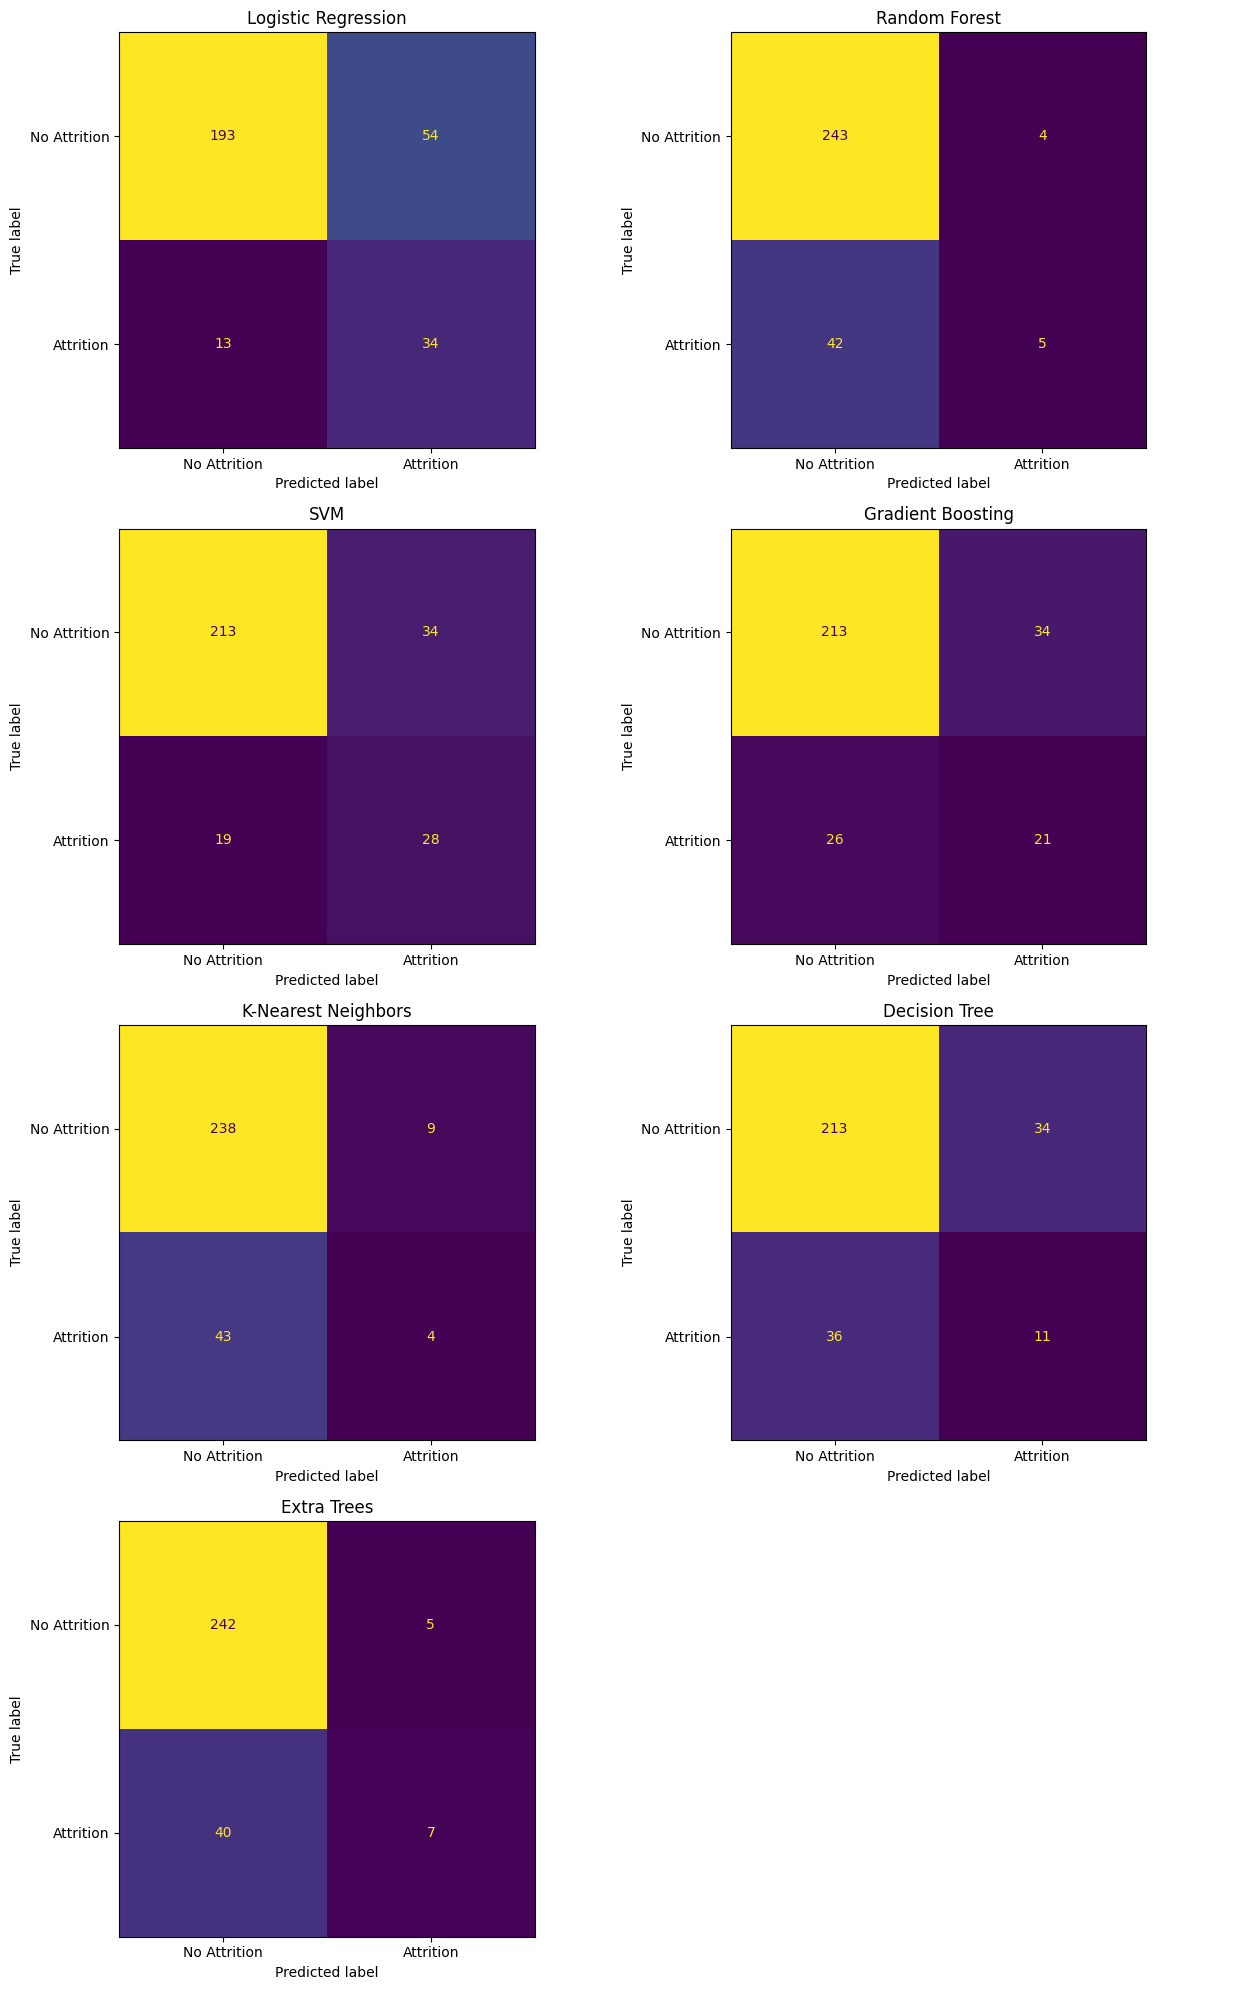

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(13, 20))
axes = axes.ravel()

for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred),
        display_labels=["No Attrition", "Attrition"]
    ).plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 6. ROC curves

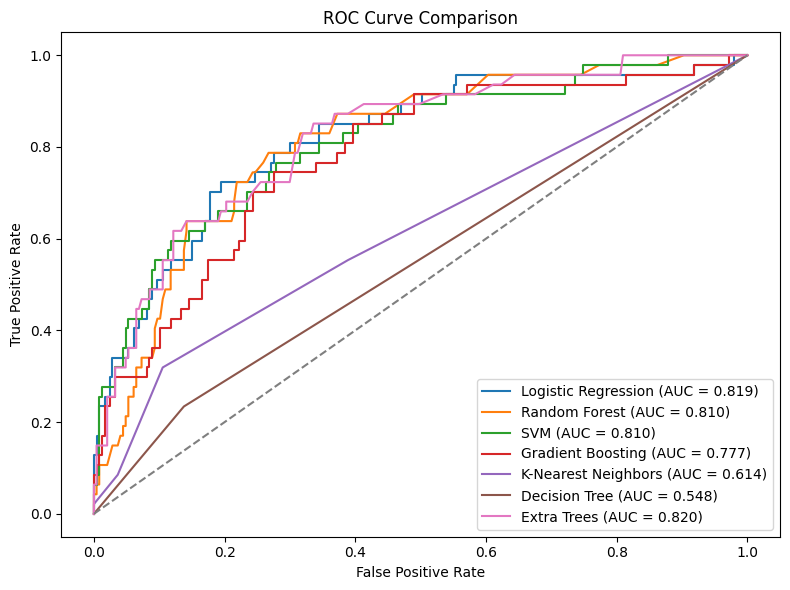

In [8]:
plt.figure(figsize=(8, 6))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Precision–Recall curves

Precision–Recall analysis is useful for this dataset because attrition is the minority class.


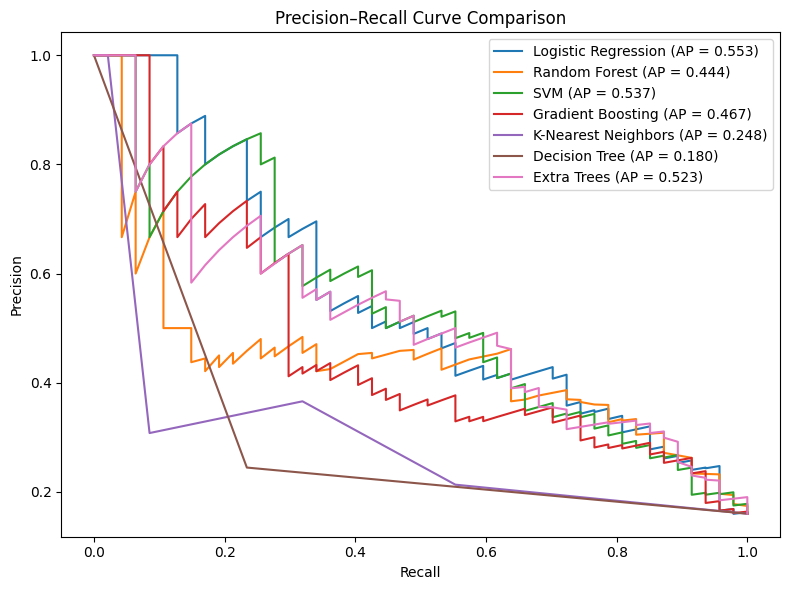

In [9]:
plt.figure(figsize=(8, 6))
for name, prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    pr_auc = average_precision_score(y_test, prob)
    plt.plot(recall, precision, label=f"{name} (AP = {pr_auc:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Classification reports

In [10]:
for name, pred in predictions.items():
    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)
    print(classification_report(
        y_test, pred,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    ))



Logistic Regression
              precision    recall  f1-score   support

No Attrition       0.94      0.78      0.85       247
   Attrition       0.39      0.72      0.50        47

    accuracy                           0.77       294
   macro avg       0.66      0.75      0.68       294
weighted avg       0.85      0.77      0.80       294


Random Forest
              precision    recall  f1-score   support

No Attrition       0.85      0.98      0.91       247
   Attrition       0.56      0.11      0.18        47

    accuracy                           0.84       294
   macro avg       0.70      0.55      0.55       294
weighted avg       0.81      0.84      0.80       294


SVM
              precision    recall  f1-score   support

No Attrition       0.92      0.86      0.89       247
   Attrition       0.45      0.60      0.51        47

    accuracy                           0.82       294
   macro avg       0.68      0.73      0.70       294
weighted avg       0.84      0.82

## 9. Save evaluation outputs

Files are saved to a `models` folder beside the notebook's project-level `backend`/`data` folders when those folders are discoverable. Otherwise, outputs are saved in the notebook's current working directory under `evaluation_outputs`.

This notebook saves comparison reports only; it does not automatically overwrite the deployed model artifact.


In [11]:
# Find an appropriate output directory without overwriting the deployed model.
output_candidates = [
    Path("../models"),
    Path("backend/models"),
    Path("../backend/models"),
    Path("models")
]
output_dir = next((path for path in output_candidates if path.exists()), None)
if output_dir is None:
    output_dir = Path("evaluation_outputs")
    output_dir.mkdir(parents=True, exist_ok=True)

cv_evaluation.to_csv(output_dir / "model_comparison_cv.csv", index=False)
test_evaluation.to_csv(output_dir / "model_comparison_test.csv", index=False)

summary = {
    "selection_method": "5-fold StratifiedKFold on training data; mean F1-score primary",
    "selected_model": best_model_name,
    "selected_model_cv_metrics": cv_results[best_model_name],
    "selected_model_test_metrics": test_rows[best_model_name],
    "models_compared": list(models.keys()),
    "random_state": 42,
    "test_size": 0.20
}
with open(output_dir / "model_evaluation_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Saved outputs to:", output_dir.resolve())
print("- model_comparison_cv.csv")
print("- model_comparison_test.csv")
print("- model_evaluation_summary.json")
print("Note: Deployed model artifact was not overwritten.")


Saved outputs to: C:\Users\kanga\Downloads\employee-attrition-prediction\backend\models
- model_comparison_cv.csv
- model_comparison_test.csv
- model_evaluation_summary.json
Note: Deployed model artifact was not overwritten.
